# Playlist Detective 1: Copycat Playlists
### MATH 3280 · Similarities: Minhashing and Locality-Sensitive Hashing

A small music-streaming startup, **Tunebasket**, has 1,000 user playlists. Each playlist is just a *set of artists*.

Some users copy someone else's playlist and change a few artists. Tunebasket wants every pair of playlists with Jaccard similarity **at least 0.6**, but without comparing all ~500,000 pairs. You will build the tools to do that: minhash signatures to shrink each playlist, then LSH to find the few pairs worth checking.

**Rules**

* Implement Jaccard similarity, minhashing, and LSH banding **yourself**.

* Use only `numpy`, `pandas`, `matplotlib`, `itertools`, `collections`, and `time`. You may use a library such as `mlxtend` or `datasketch` *only* to double-check your answers, and you must say so if you do.
* Every cell marked `# TODO` needs code. Every "**Your answer**" cell needs a few sentences.
* Run the whole notebook top to bottom (*Kernel → Restart & Run All*) before you submit.

All artist names are fictional.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter, defaultdict
import time

SEED = 3280
rng = np.random.default_rng(SEED)

## Part 0 · Load and explore the data (10 pts)

`playlists.csv` has one row per (playlist, artist). Build:

* `baskets`: a dictionary `playlist_id -> {set of artists}`
* `artists`: a sorted list of all artists, and `artist_index`: a dictionary `artist -> row number`
* `playlist_ids`: a sorted list of playlist ids
* `M`: the characteristic (utility) matrix, a 0/1 NumPy array with one row per artist and one column per playlist, so `M[i, j] = 1` when artist `i` is in playlist `j`.

In [18]:
df = pd.read_csv("playlists.csv")

# Go through the CSV row by row and add each artist to its playlist's set
baskets = {}
for p, a in zip(df["playlist_id"], df["artist"]):
    if p not in baskets:
        baskets[p] = set()        # first time seeing this playlist: start an empty set
    baskets[p].add(a)

playlist_ids = sorted(baskets.keys())

artists = sorted(set(df["artist"]))

# Give each artist a row number: 0, 1, 2, ...
artist_index = {}
for i, a in enumerate(artists):
    artist_index[a] = i

# Start with all zeros, then put a 1 wherever an artist is in a playlist
M = np.zeros((len(artists), len(playlist_ids)), dtype=int)
for j, p in enumerate(playlist_ids):
    for a in baskets[p]:
        i = artist_index[a]
        M[i, j] = 1

print("playlists:", len(playlist_ids), " artists:", len(artists), " M shape:", M.shape)


playlists: 1000  artists: 481  M shape: (481, 1000)


In [19]:
# Quick look: playlist sizes and the most common artists
sizes = pd.Series({p: len(s) for p, s in baskets.items()})
print(sizes.describe())
print(df["artist"].value_counts().head(10))

count    1000.000000
mean       16.814000
std         4.486818
min         8.000000
25%        13.000000
50%        17.000000
75%        20.000000
max        29.000000
dtype: float64
artist
Nova Lux                463
The Glass Meadow        158
The Paper Rivers        138
The Electric Circuit    135
The Neon Rivers         131
The Midnight Orchard    122
The Thunder Wolves      119
The Frozen Comets       114
The Wild Comets         107
The Electric Foxes      105
Name: count, dtype: int64


**Q0.** How many of the $\binom{1000}{2}$ pairs of playlists would a brute-force search compare? What fraction of the matrix `M` is 1s? Why does that sparsity matter for how real systems store this matrix?

**Your answer:** 

## Part 1 · Warm-up: Jaccard similarity and the S-curve (15 pts)

Write three small functions, then check them with the `assert` cell.

* `jaccard(A, B)` $= |A \cap B| / |A \cup B|$
* `candidate_prob(s, b, r)` $= 1 - (1 - s^r)^b$, the probability that two sets with similarity $s$ become an LSH candidate pair with $b$ bands of $r$ rows
* `lsh_threshold(b, r)` $\approx (1/b)^{1/r}$, the similarity where the S-curve rises most steeply

In [20]:
def jaccard(A, B):
    # |A ∩ B| / |A ∪ B|
    A, B = set(A), set(B)          # so strings like "john" become sets of letters
    union = A | B
    if not union:                  # both sets empty: define similarity as 0
        return 0.0
    return len(A & B) / len(union)

def candidate_prob(s, b, r):
    # 1 - (1 - s^r)^b  (works for a single s or a NumPy array of s values)
    return 1 - (1 - s**r)**b

def lsh_threshold(b, r):
    # (1/b)^(1/r)
    return (1 / b) ** (1 / r)

In [21]:
assert abs(jaccard({1, 2, 3}, {2, 3, 4}) - 0.5) < 1e-9
assert abs(jaccard("john", "joan") - 3/5) < 1e-9          # letters as sets: {j,o,h,n} vs {j,o,a,n}
assert jaccard({1, 2}, {3, 4}) == 0
assert abs(candidate_prob(0.8, 20, 5) - 0.99964) < 1e-4    # the textbook's b = 20, r = 5 example
assert abs(lsh_threshold(20, 5) - 0.5493) < 1e-3
print("Part 1 checks passed.")

Part 1 checks passed.


## Part 2 · Minhashing (30 pts)

Permuting 481 rows hundreds of times is slow, so we simulate each permutation with a hash function

$$h_i(x) = (a_i x + b_i) \bmod p,$$

where $x$ is the row number, $p$ is a prime larger than the number of rows, and $a_i, b_i$ are random integers with $1 \le a_i < p$ and $0 \le b_i < p$.

**2a.** Write `minhash_signatures(M, n_hashes, seed)` that returns the $n \times (\text{\# playlists})$ signature matrix using the row-by-row algorithm from the notes:

1. Start every signature entry at a very large value. For example, $SIG[i, c] = 99999$.
2. For each row $r$: compute $h_1(r), \dots, h_n(r)$. For each column $c$ with $M[r, c] = 1$, replace $SIG[i, c]$ by $\min(SIG[i, c],\, h_i(r))$.

*(Hint: for one row, you can update all of its columns at once with `np.minimum`.)*

In [24]:
P = 4_294_967_311  # a prime larger than 2^32

def make_hashes(n_hashes, seed=SEED):
    g = np.random.default_rng(seed)
    a = g.integers(1, P, size=n_hashes, dtype=np.int64)
    b = g.integers(0, P, size=n_hashes, dtype=np.int64)
    return a, b

def minhash_signatures(M, n_hashes, seed=SEED):
    a, b = make_hashes(n_hashes, seed)
    n_rows, n_cols = M.shape

    # Step 1: start every entry at "infinity". Hash values go up to P (~4.3 billion),
    # so 99999 would be too small; P itself is larger than any hash value.
    SIG = np.full((n_hashes, n_cols), P, dtype=np.int64)

    # Step 2: go through the rows one at a time
    for r in range(n_rows):
        h = (a * r + b) % P              # h_1(r), ..., h_n(r): one value per hash function
        cols = np.nonzero(M[r])[0]       # the columns (playlists) that have a 1 in this row
        if len(cols) == 0:
            continue
        # for those columns, keep the smaller of the current signature and h_i(r)
        SIG[:, cols] = np.minimum(SIG[:, cols], h[:, None])

    return SIG

def estimated_jaccard(SIG, c1, c2):
    # fraction of signature rows where columns c1 and c2 agree
    return np.mean(SIG[:, c1] == SIG[:, c2])

In [25]:
# Checks
SIG = minhash_signatures(M, 100)
assert SIG.shape == (100, len(playlist_ids))
same = minhash_signatures(np.array([[1, 1], [0, 0], [1, 1]]), 50)
assert estimated_jaccard(same, 0, 1) == 1.0          # identical columns always agree
print("Part 2a checks passed.")

Part 2a checks passed.


**2b. How good is the estimate?** Pick 200 random pairs of playlists **plus** the pair `("P0265", "P0473")`. For $n \in \{10, 25, 50, 100, 200, 400\}$ hash functions, compute the mean absolute error between the minhash estimate and the true Jaccard similarity. Plot error vs. $n$.

     n  mean abs error
0   10        0.021561
1   25        0.014667
2   50        0.008640
3  100        0.009627
4  200        0.005400
5  400        0.004474
P0265 vs P0473: true J = 0.913


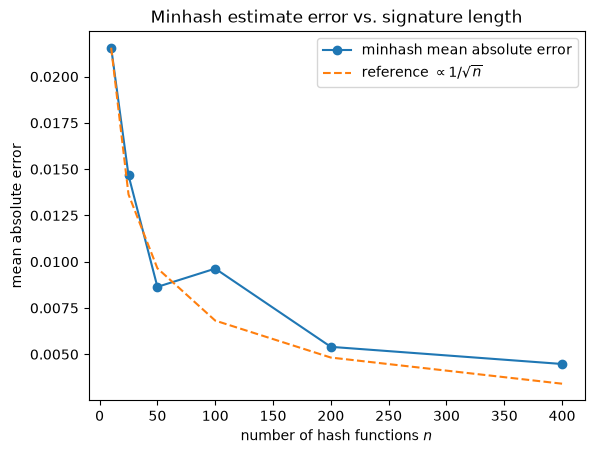

In [26]:
col = {p: j for j, p in enumerate(playlist_ids)}
pair_rng = np.random.default_rng(1)
test_pairs = [tuple(pair_rng.choice(len(playlist_ids), 2, replace=False)) for _ in range(200)]
test_pairs.append((col["P0265"], col["P0473"]))

# True Jaccard for each test pair (computed exactly from the sets)
true_J = np.array([jaccard(baskets[playlist_ids[c1]], baskets[playlist_ids[c2]])
                   for c1, c2 in test_pairs])

# Mean absolute error of the minhash estimate for each number of hash functions
n_values = [10, 25, 50, 100, 200, 400]
mae = []
for n in n_values:
    SIG_n = minhash_signatures(M, n)
    est_J = np.array([estimated_jaccard(SIG_n, c1, c2) for c1, c2 in test_pairs])
    mae.append(np.mean(np.abs(est_J - true_J)))

print(pd.DataFrame({"n": n_values, "mean abs error": mae}))
print("P0265 vs P0473: true J =", round(true_J[-1], 4))

# Plot error vs n, with a c/sqrt(n) reference curve for comparison
plt.plot(n_values, mae, "o-", label="minhash mean absolute error")
plt.plot(n_values, mae[0] * np.sqrt(n_values[0]) / np.sqrt(n_values), "--",
         label=r"reference $\propto 1/\sqrt{n}$")
plt.xlabel("number of hash functions $n$")
plt.ylabel("mean absolute error")
plt.title("Minhash estimate error vs. signature length")
plt.legend()
plt.show()

**Q2.** Each signature row agrees with probability $J$, so the estimate is a sample proportion. Its standard error is $\sqrt{J(1-J)/n}$. Does your plot shrink like $1/\sqrt{n}$? How many hash functions would you need so the standard error is at most 0.05 for a pair with $J = 0.5$?

**Your answer:** *write here*

## Part 3 · Locality-Sensitive Hashing (45 pts)

Split the $n = 100$ signature rows into $b$ bands of $r$ rows ($br = 100$). Two playlists become a **candidate pair** if their signatures agree on *every* row of *at least one* band.

**3a.** Using your Part 1 functions, plot the S-curve for every $(b, r)$ with $br = 100$ and $r \in \{2, 4, 5, 10, 20\}$. Mark the target $s = 0.6$. Choose a $(b, r)$ for this job, and justify your choice in terms of false positives and false negatives.

In [ ]:
s = np.linspace(0, 1, 201)
# TODO: plot candidate_prob(s, b, r) for each (b, r), and mark s = 0.6

**Your answer:** *write here*

**3b.** Write `lsh_candidates(SIG, b, r)`. For each band, use the tuple of that band's $r$ values as a bucket key (a dictionary is a hash table). Every pair of columns that share a bucket in any band is a candidate. Return a **set** of `(i, j)` pairs with `i < j`.

In [ ]:
def lsh_candidates(SIG, b, r):
    assert SIG.shape[0] == b * r
    cands = set()
    # TODO: for each band, bucket the columns by their band values; add all pairs in a shared bucket
    return cands

**3c. Does it work?** Using your $(b, r)$:

1. Time the LSH step and the follow-up step that keeps candidates whose **exact** Jaccard is $\ge 0.6$.
2. Time a brute-force search over all pairs for the true answer.
3. Report the number of candidates, true positives, false positives (candidates with $J < 0.6$), and false negatives (true pairs LSH missed).

In [ ]:
THRESH = 0.6
B_, R_ = ..., ...   # TODO: your choice from 3a
sets = [baskets[p] for p in playlist_ids]

# TODO: time (minhash + LSH + exact check of candidates)
# TODO: time a brute-force search over all pairs
# TODO: report candidates, true positives, false positives, false negatives; list the pairs you found

**3d.** Repeat 3c for two other $(b, r)$ choices, one with a higher threshold and one with a lower threshold. Put the results in a small table (`pd.DataFrame`).

In [ ]:
# TODO: build a table comparing (b, r) choices

**Q3.** Explain the trade-off you see in your table. In a real system with 100 million playlists, why is a false positive much cheaper than a false negative here?

**Your answer:** *write here*

## Submission checklist

* [ ] Notebook runs top to bottom with no errors
* [ ] All `assert` checks pass
* [ ] Every **Your answer** cell is filled in
* [ ] Plots have axis labels
* [ ] Any library used to double-check answers is named and discussed